# Population change point: example traces around the f ~ 200-300 pA bump

Detection performance improves for f ~ 200-300 pA and then drops again. This notebook looks at the raw responses
behind that, for variance = 25 pA² and small steps (dH ≤ 5 pA):

1. single neuron responses: membrane voltage (re-simulated) and spike rasters (saved trials)
2. population PSTHs of k trials, as scored by the PSTH change point analysis

In [1]:
import inspect
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()
warnings.filterwarnings('ignore')

from CPA_with_AQUA import *

In [2]:
tag = 'N250'
SAVE = False
V = 25.0                            # pA², noise variance
F_EX = [220, 280, 300, 320, 350, 400]  # pA, autapse strengths
H_EX = [0, 2, 4, 6, 8]            # pA, step heights
T_DISCARD = 200     # ms, initial transient
PSTH_BIN = 25       # ms
K = 10              # trials per PSTH
N_RES = 20          # resamples per condition
F_COLORS = dict(zip(F_EX, sns.color_palette('viridis', len(F_EX))))

sim = {k: p.default for k, p in inspect.signature(simulate_runs).parameters.items()
       if p.default is not inspect.Parameter.empty}

with open(f'CPA_cusum_mean_{tag}_spikes.pickle', 'rb') as file:
    saved = pickle.load(file)
T, true_cp, N_REP = saved['T'], saved['changepoint'], saved['N_repeats']
CONDITIONS = [(v, h, f) for v in saved['var'] for h in saved['d_H'] for f in saved['f_values']]
print(f"repeats: {N_REP}, T = {T} ms, change point at {true_cp} ms, e = {sim['e']}, τ = {sim['tau']} ms")


def spikes(rep, h, f):
    s = np.asarray(saved['spikes'][(rep, V, h, f)], dtype = float)
    return s[~np.isnan(s)]


def condition_psths(v, h, f, seed = 0):
    '''the N_RES k-trial PSTHs (raw counts) psth_cusum_analysis scored for this condition (same seed)'''
    i = CONDITIONS.index((v, h, f))
    trials = [saved['spikes'][(rep, v, h, f)] for rep in range(N_REP)]
    return psth_resamples(trials, K, N_RES, PSTH_BIN, T, T_DISCARD, np.random.default_rng([seed, i]))

repeats: 250, T = 10000 ms, change point at 5000 ms, e = 0.2, τ = 2.0 ms


## 1a. Membrane voltage (re-simulated)

The saved pickle only holds spike times, so one repeat is re-simulated with `simulate_runs(save_all = True)`
for just these conditions. **These are new noise draws, not the saved trials.** Within each step height
all f values receive the same noisy current, so columns differ only by the autapse.

In [3]:
SEED = 0
np.random.seed(SEED)     # fixed so the injected current can be rebuilt in section 3
reps, (X, t, Sp) = next(simulate_runs(RS, np.array(F_EX), np.array(H_EX), np.array([V]), N_repeats = 1,
                                      T = T, changepoint = true_cp, save_all = True))
Vm = X[:, 0, :]     # membrane voltage only
del X
idx = lambda f, h: find_idx(f, V, h, np.array(F_EX), np.array([V]), np.array(H_EX))
print(Vm.shape)

Repeats 0-0 of 1


100%|██████████| 99999/99999 [00:12<00:00, 7943.96it/s]

(30, 100000)


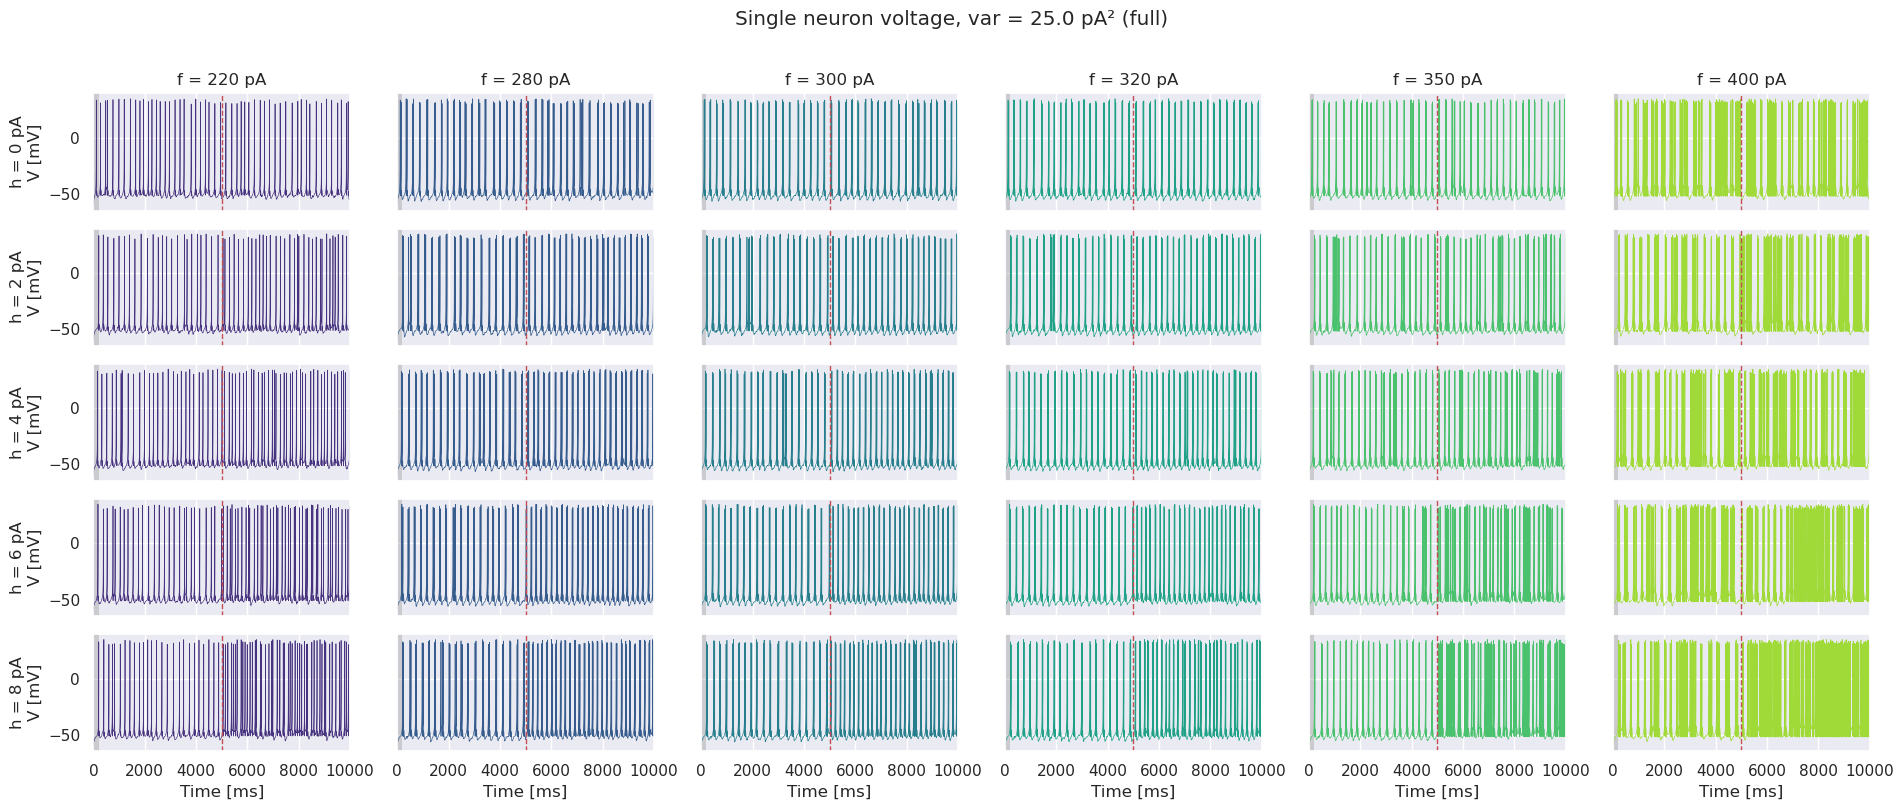

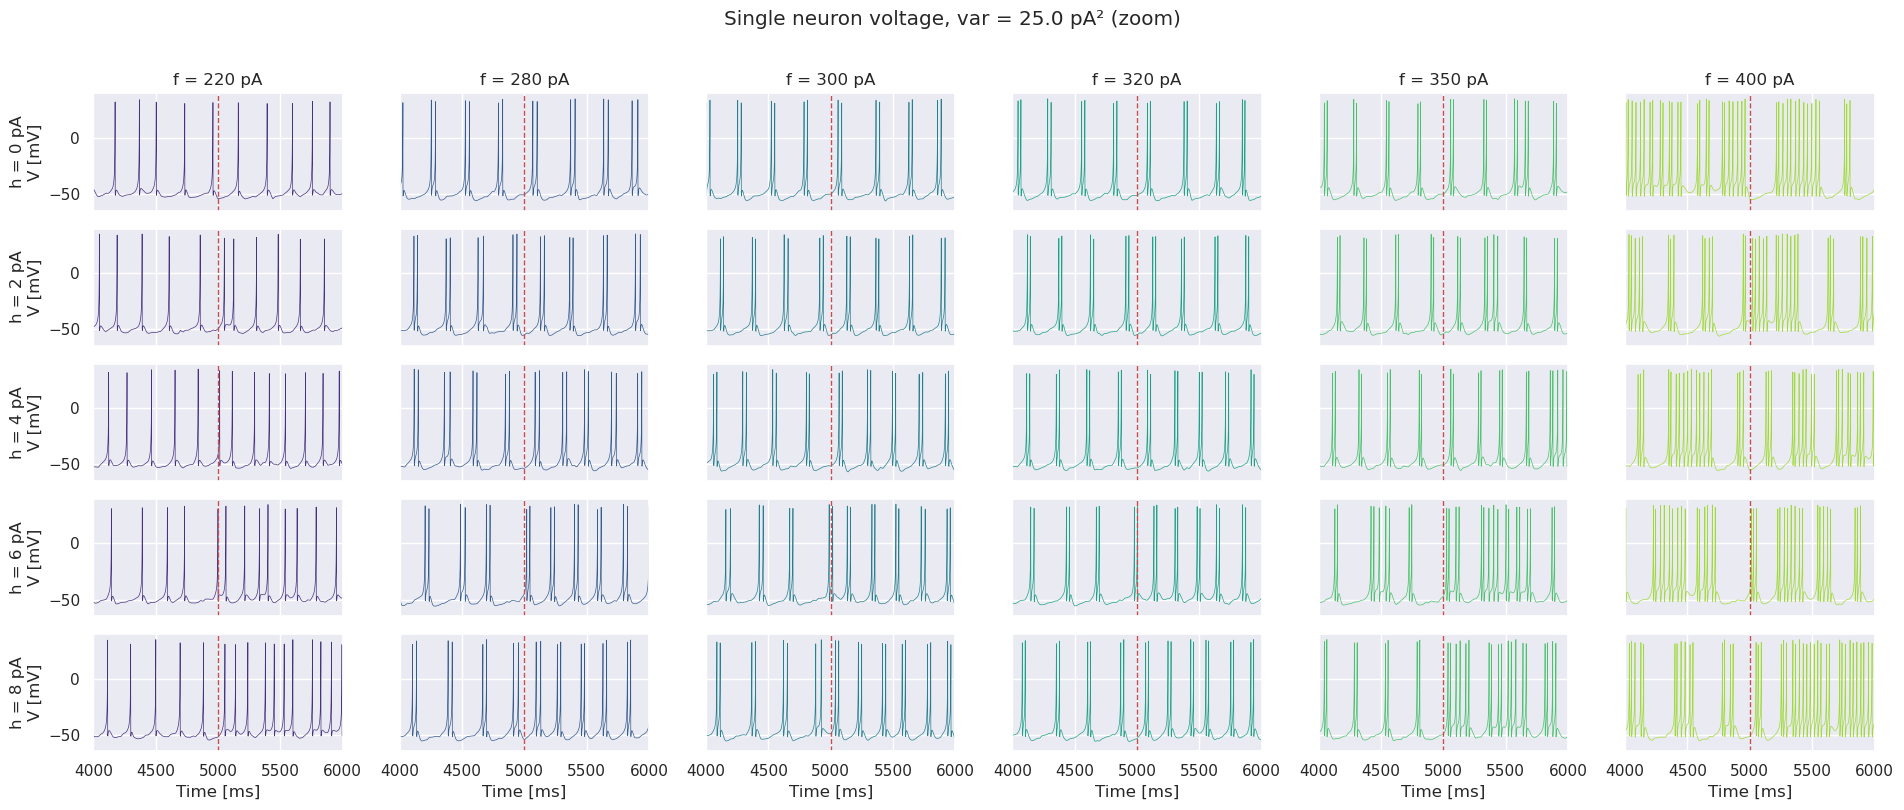

In [4]:
for xlim, name in [((0, T), 'full'), ((true_cp - 1000, true_cp + 1000), 'zoom')]:
    fig, ax = plt.subplots(len(H_EX), len(F_EX), figsize = (3.2*len(F_EX), 1.6*len(H_EX)), sharex = True, sharey = True)
    for r, h in enumerate(H_EX):
        for c, f in enumerate(F_EX):
            a = ax[r, c]
            a.plot(t, Vm[idx(f, h)], color = F_COLORS[f], lw = 0.5)
            a.axvline(true_cp, color = 'r', ls = '--', lw = 1)
            a.axvspan(0, T_DISCARD, color = 'grey', alpha = 0.3, lw = 0)
            a.set_xlim(*xlim)
            if r == 0: a.set_title(f'f = {f} pA')
            if c == 0: a.set_ylabel(f'h = {h} pA\nV [mV]')
    for a in ax[-1]: a.set_xlabel('Time [ms]')
    fig.suptitle(f'Single neuron voltage, var = {V} pA² ({name})', y = 1.01)
    fig.tight_layout()
    if SAVE: plt.savefig(f'./plots/{tag}_traces_voltage_{name}.png', bbox_inches = 'tight')
    plt.show()

## 1b. Spike rasters (saved trials)

First 20 saved repeats per condition: the same trials the population analysis uses.

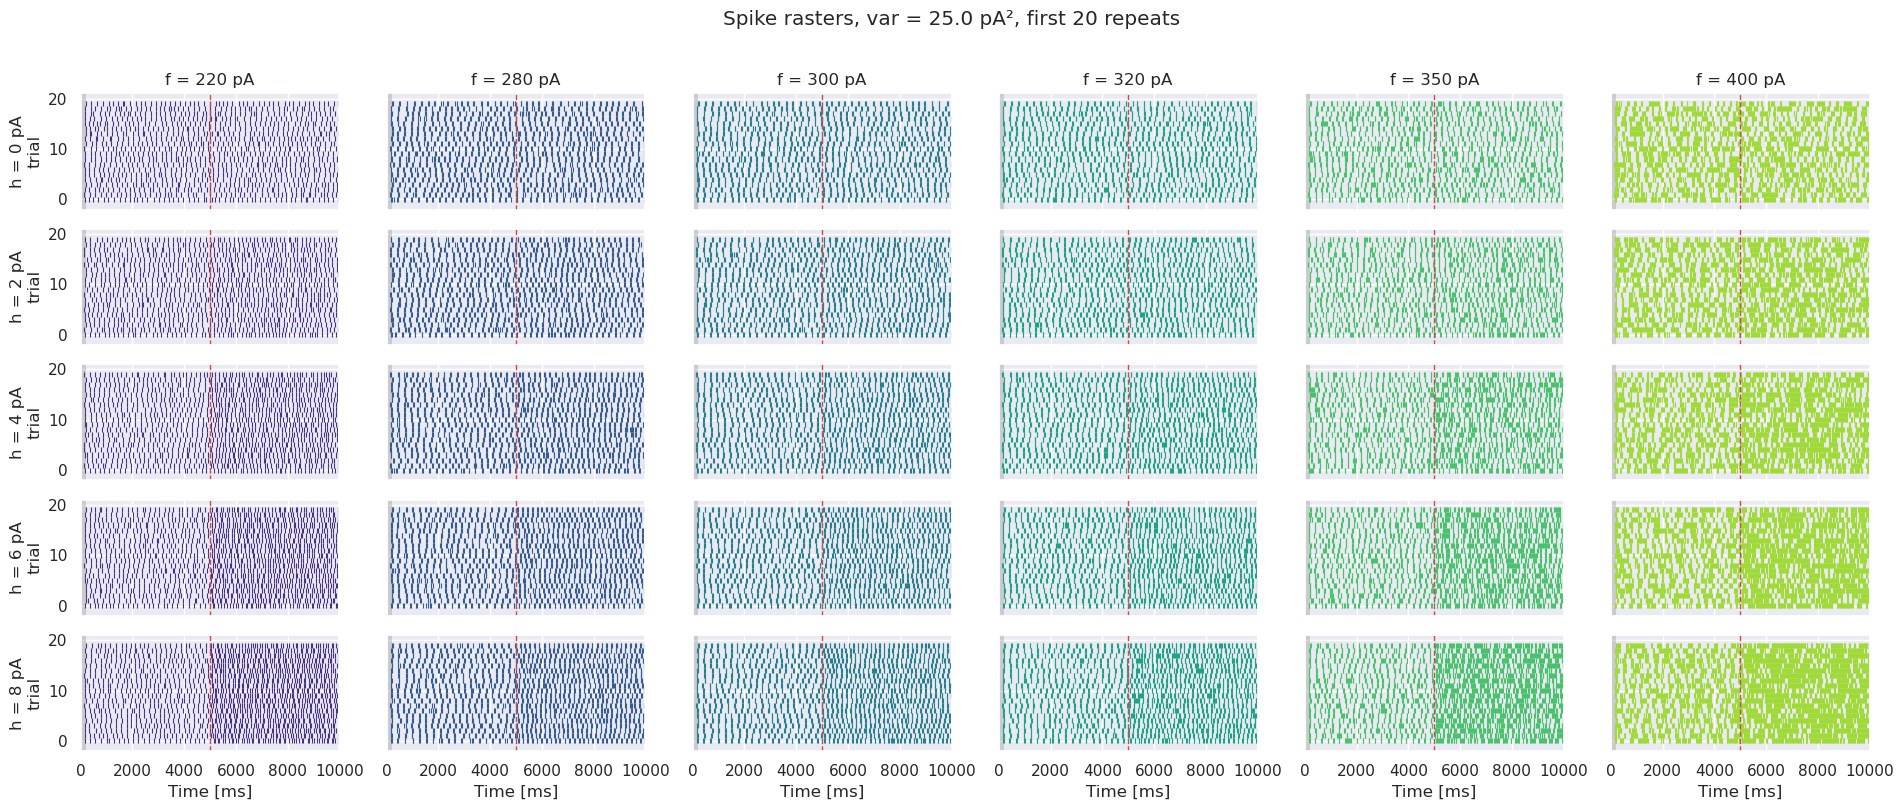

In [5]:
N_SHOW = 20
fig, ax = plt.subplots(len(H_EX), len(F_EX), figsize = (3.2*len(F_EX), 1.6*len(H_EX)), sharex = True, sharey = True)
for r, h in enumerate(H_EX):
    for c, f in enumerate(F_EX):
        a = ax[r, c]
        a.eventplot([spikes(rep, h, f) for rep in range(N_SHOW)], color = F_COLORS[f], lw = 0.8)
        a.axvline(true_cp, color = 'r', ls = '--', lw = 1)
        a.axvspan(0, T_DISCARD, color = 'grey', alpha = 0.3, lw = 0)
        a.set_xlim(0, T)
        if r == 0: a.set_title(f'f = {f} pA')
        if c == 0: a.set_ylabel(f'h = {h} pA\ntrial')
for a in ax[-1]: a.set_xlabel('Time [ms]')
fig.suptitle(f'Spike rasters, var = {V} pA², first {N_SHOW} repeats', y = 1.01)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_traces_rasters.png', bbox_inches = 'tight')
plt.show()

## 1b'. ISI distributions, pre vs post (saved trials)

ISIs pooled over all saved repeats, before and after the CP (ISIs straddling the CP and the initial transient are dropped).
Log time axis, so burst doublets (~10 ms) and regular ISIs (~200 ms) are both visible.

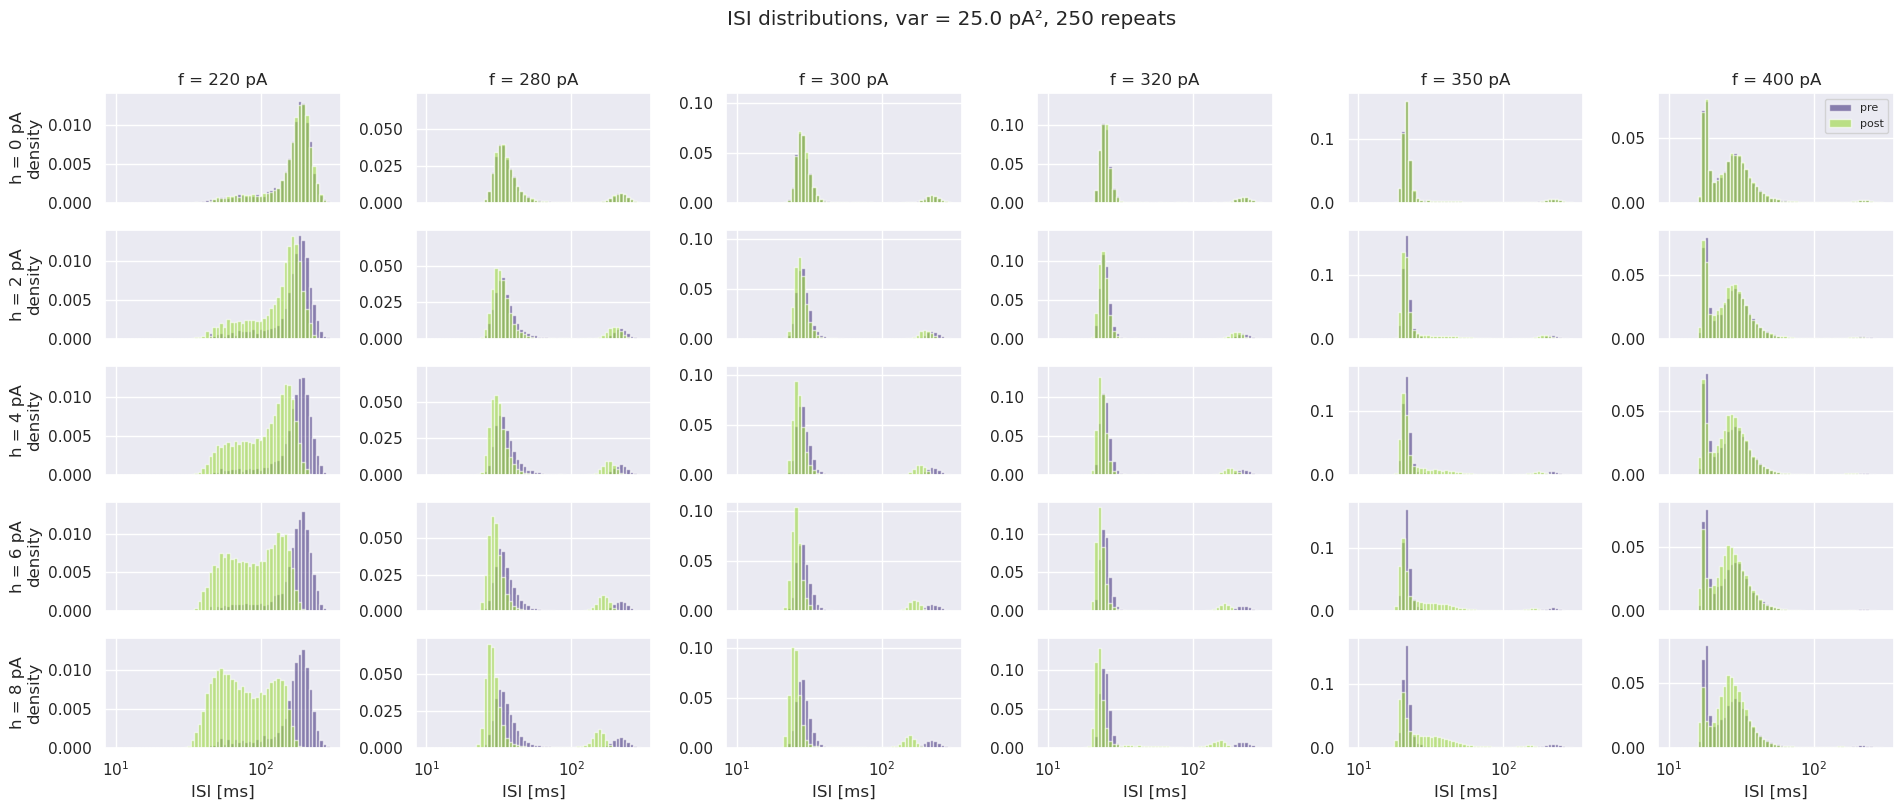

In [18]:
ISI_BINS = np.geomspace(10, 300, 61)    # ms
fig, ax = plt.subplots(len(H_EX), len(F_EX), figsize = (3.2*len(F_EX), 1.6*len(H_EX)), sharex = 'col', sharey = 'col')
for r, h in enumerate(H_EX):
    for c, f in enumerate(F_EX):
        a = ax[r, c]
        trials = [spikes(rep, h, f) for rep in range(N_REP)]
        pre, post = reference_isis([(np.diff(s[s >= T_DISCARD]), s[s >= T_DISCARD][1:]) for s in trials], true_cp)
        a.hist(pre, bins = ISI_BINS, density = True, alpha = 0.6, color = plt.cm.viridis(0.15), label = 'pre')
        a.hist(post, bins = ISI_BINS, density = True, alpha = 0.6, color = plt.cm.viridis(0.85), label = 'post')
        a.set_xscale('log')
        if r == 0: a.set_title(f'f = {f} pA')
        if c == 0: a.set_ylabel(f'h = {h} pA\ndensity')
for a in ax[-1]: a.set_xlabel('ISI [ms]')
ax[0, -1].legend(fontsize = 8)
fig.suptitle(f'ISI distributions, var = {V} pA², {N_REP} repeats', y = 1.01)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_traces_isi_dists.png', bbox_inches = 'tight')
plt.show()

## 1c. Single neuron rate change and regularity

From all saved repeats: pre (T_DISCARD to CP) and post (CP to T) firing rates, and the CV of the pooled pre/post ISIs.
A detector does best where the rate jump is large relative to spiking variability: look for whether Δrate or the CV
moves non-monotonically over f ~ 200-300 pA.

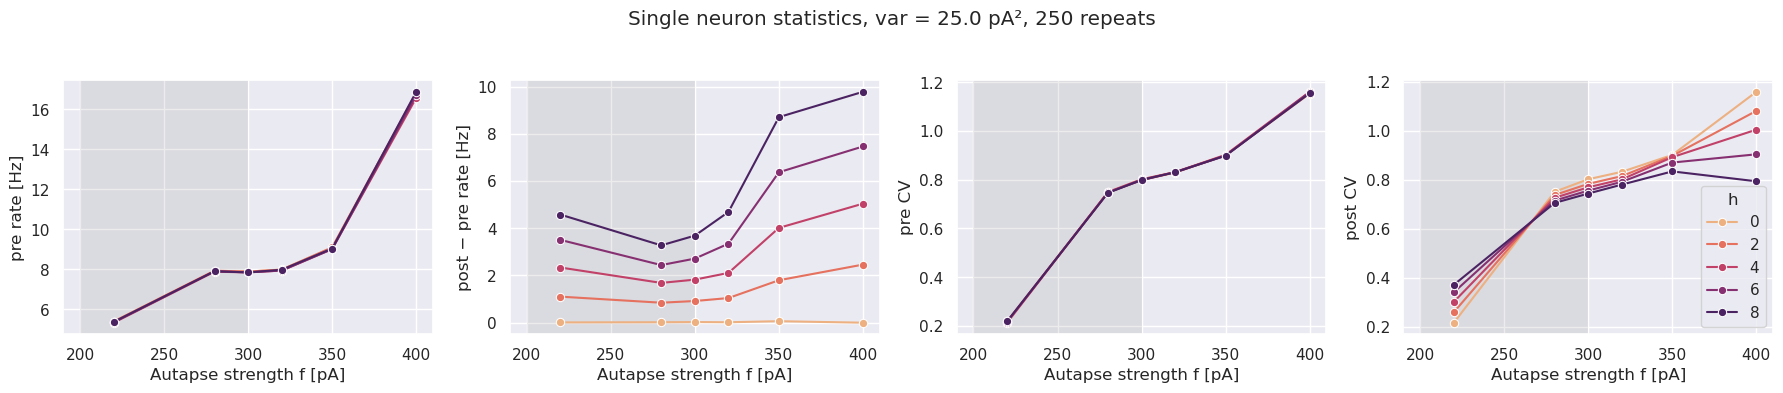

f,220,280,300,320,350,400
h,,,,,,
0,0.01,0.02,0.02,0.02,0.06,-0.00
2,1.10,0.84,0.92,1.04,1.80,2.46
4,2.34,1.68,1.82,2.11,4.02,5.04
6,3.51,2.44,2.71,3.35,6.37,7.47
8,4.58,3.28,3.69,4.69,8.71,9.78


In [7]:
rows = []
for h in H_EX:
    for f in F_EX:
        trials = [spikes(rep, h, f) for rep in range(N_REP)]
        pre_rate = np.mean([np.sum((s >= T_DISCARD) & (s < true_cp)) for s in trials]) / (true_cp - T_DISCARD) * 1e3
        post_rate = np.mean([np.sum(s >= true_cp) for s in trials]) / (T - true_cp) * 1e3
        isis = [(np.diff(s[s >= T_DISCARD]), s[s >= T_DISCARD][1:]) for s in trials]
        pre, post = reference_isis(isis, true_cp)
        rows.append({'f': f, 'h': h, 'pre rate': pre_rate, 'post rate': post_rate, 'Δrate': post_rate - pre_rate,
                     'pre CV': pre.std() / pre.mean(), 'post CV': post.std() / post.mean()})
single = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 4, figsize = (18, 3.8))
for a, y in zip(ax, ['pre rate', 'Δrate', 'pre CV', 'post CV']):
    sns.lineplot(single, x = 'f', y = y, hue = 'h', palette = 'flare', marker = 'o', ax = a, legend = a is ax[-1])
    a.axvspan(200, 300, color = 'grey', alpha = 0.15, lw = 0)
    a.set_xlabel('Autapse strength f [pA]')
ax[0].set_ylabel('pre rate [Hz]'); ax[1].set_ylabel('post − pre rate [Hz]')
fig.suptitle(f'Single neuron statistics, var = {V} pA², {N_REP} repeats', y = 1.03)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_traces_single_stats.png', bbox_inches = 'tight')
plt.show()
single.pivot(index = 'h', columns = 'f', values = 'Δrate').round(2)

## 2a. Population PSTHs

The same k-trial resamples (same seeds) the PSTH change point analysis scored. Blue: mean ± sd over resamples;
black: one resample, i.e. a single input to a detector.

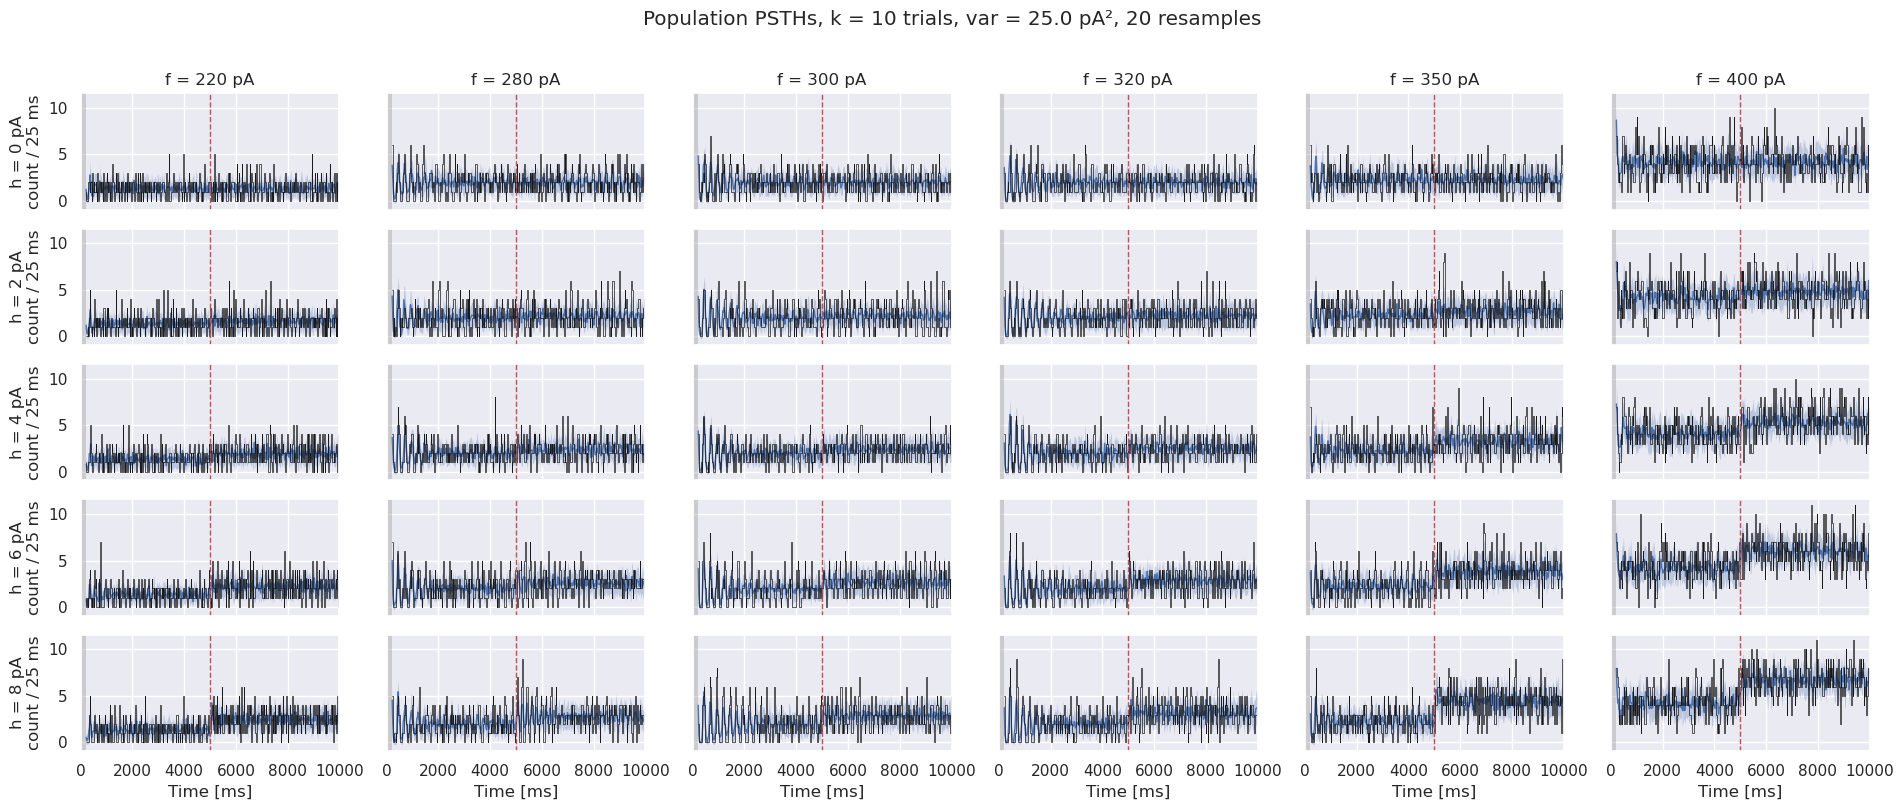

In [8]:
fig, ax = plt.subplots(len(H_EX), len(F_EX), figsize = (3.2*len(F_EX), 1.6*len(H_EX)), sharex = True, sharey = True)
for r, h in enumerate(H_EX):
    for c, f in enumerate(F_EX):
        a = ax[r, c]
        X, t_bin = condition_psths(V, h, f)
        tc = t_bin - PSTH_BIN/2
        mu, sd = X.mean(0), X.std(0)
        a.fill_between(tc, mu - sd, mu + sd, color = 'C0', alpha = 0.3, lw = 0)
        a.plot(tc, mu, color = 'C0', lw = 1)
        a.step(tc, X[0], where = 'mid', color = 'k', lw = 0.5)
        a.axvline(true_cp, color = 'r', ls = '--', lw = 1)
        a.axvspan(0, T_DISCARD, color = 'grey', alpha = 0.3, lw = 0)
        a.set_xlim(0, T)
        if r == 0: a.set_title(f'f = {f} pA')
        if c == 0: a.set_ylabel(f'h = {h} pA\ncount / {PSTH_BIN} ms')
for a in ax[-1]: a.set_xlabel('Time [ms]')
fig.suptitle(f'Population PSTHs, k = {K} trials, var = {V} pA², {N_RES} resamples', y = 1.01)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_traces_psth.png', bbox_inches = 'tight')
plt.show()

## 2b. PSTH pre/post separation

Per condition, the bin counts of all resamples pooled before and after the CP (`reference_bins`), summarised as
d′ = (post mean − pre mean) / pooled sd. This is the signal-to-noise a PSTH detector sees.

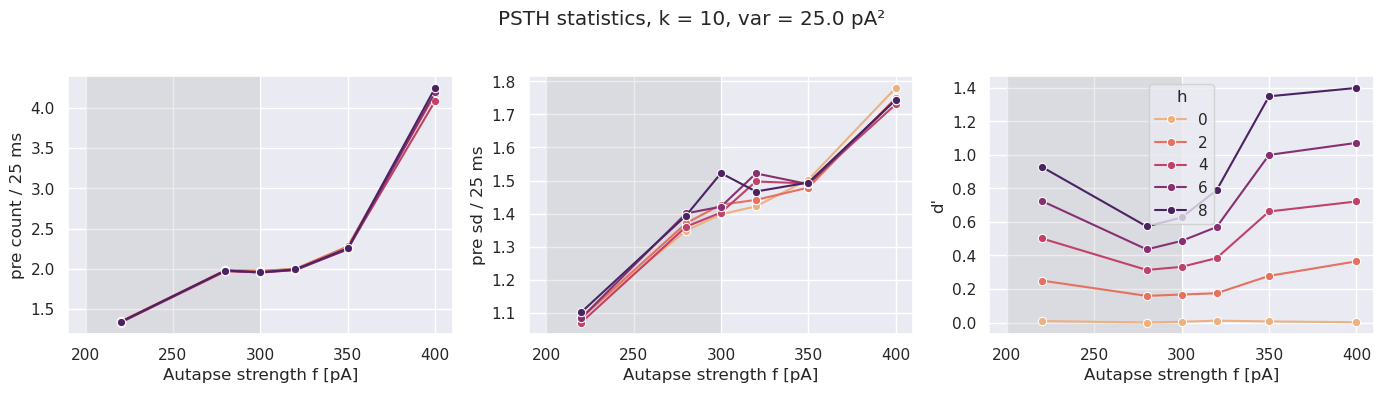

f,220,280,300,320,350,400
h,,,,,,
0,0.01,-0.00,0.00,0.01,0.01,0.00
2,0.25,0.16,0.17,0.17,0.28,0.37
4,0.50,0.31,0.33,0.38,0.66,0.72
6,0.73,0.44,0.49,0.57,1.00,1.07
8,0.93,0.57,0.63,0.79,1.35,1.40


In [9]:
rows = []
for h in H_EX:
    for f in F_EX:
        X, t_bin = condition_psths(V, h, f)
        pre, post = reference_bins(X, t_bin, PSTH_BIN, true_cp)
        rows.append({'f': f, 'h': h, 'pre mean': pre.mean(), 'pre sd': pre.std(),
                     "d'": (post.mean() - pre.mean()) / np.sqrt((pre.var() + post.var()) / 2)})
pop = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 3, figsize = (14, 3.8))
for a, y in zip(ax, ['pre mean', 'pre sd', "d'"]):
    sns.lineplot(pop, x = 'f', y = y, hue = 'h', palette = 'flare', marker = 'o', ax = a, legend = a is ax[-1])
    a.axvspan(200, 300, color = 'grey', alpha = 0.15, lw = 0)
    a.set_xlabel('Autapse strength f [pA]')
ax[0].set_ylabel(f'pre count / {PSTH_BIN} ms'); ax[1].set_ylabel(f'pre sd / {PSTH_BIN} ms')
fig.suptitle(f'PSTH statistics, k = {K}, var = {V} pA²', y = 1.03)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_traces_psth_stats.png', bbox_inches = 'tight')
plt.show()
pop.pivot(index = 'h', columns = 'f', values = "d'").round(2)

## 3. Summary: dH = 5 pA, var = 25 pA², f = 0

Injected current and membrane voltage are the section 1a run (current rebuilt from the same seed), not one of the saved trials.
Raster: all saved trials. ISIs: pooled over all saved trials (histograms), single 1a trial overlaid as rug ticks.

In [10]:
H_S, F_S = 5, 0
PURPLE = sns.color_palette('Purples', as_cmap = True)
C_PRE, C_POST, C_DARK, C_SHADE = PURPLE(0.45), PURPLE(0.9), PURPLE(1.0), PURPLE(0.12)

# rebuild 1a's injected current: simulate_runs draws one noise vector per h (H_EX order) after np.random.seed(SEED)
noise_steps = int(1/sim['noise_rate'] * (1000/sim['dt']))    # same formula as simulate_runs
np.random.seed(SEED)
draws = [np.random.normal(size = len(t) // noise_steps) for _ in H_EX]
I = sim['I_0'] + H_S * (t >= true_cp) + np.repeat(draws[H_EX.index(H_S)] * np.sqrt(V), noise_steps)
assert len(I) == len(t)

v_ex = Vm[idx(F_S, H_S)]
s_ex = np.asarray(Sp[idx(F_S, H_S)], dtype = float)
s_ex = s_ex[~np.isnan(s_ex)]
trials = [spikes(rep, H_S, F_S) for rep in range(N_REP)]
pre, post = reference_isis([(np.diff(s[s >= T_DISCARD]), s[s >= T_DISCARD][1:]) for s in trials], true_cp)
pre_ex, post_ex = reference_isis([(np.diff(s_ex[s_ex >= T_DISCARD]), s_ex[s_ex >= T_DISCARD][1:])], true_cp)

with sns.axes_style('white'):
    fig, ax = plt.subplots(4, 1, figsize = (10, 10), height_ratios = [1, 1.5, 2, 1.8])
    for a in ax[1:3]: a.sharex(ax[0])
    ax[0].plot(t, I, color = C_DARK, lw = 0.6)
    ax[0].plot(t, sim['I_0'] + H_S * (t >= true_cp), color = 'k', ls = ':', lw = 1.5)    # mean current
    ax[0].set_ylabel('I [pA]')
    ax[1].plot(t, v_ex, color = C_DARK, lw = 0.5)
    ax[1].set_ylabel('V [mV]')
    ax[2].eventplot(trials, color = C_POST, lw = 0.8)
    ax[2].set_ylabel('trial')
    ax[2].set_xlabel('Time [ms]')
    for a in ax[:3]:
        a.axvspan(0, T_DISCARD, color = C_SHADE, lw = 0)
        a.axvline(true_cp, color = C_DARK, ls = '--', lw = 1)
        a.set_xlim(0, T)
    for a in ax[:2]: a.tick_params(labelbottom = False)

    a = ax[3]
    bins = np.linspace(0, np.percentile(pre, 99.5) * 1.2, 50)    # linear ms axis: f = 0 has no burst ISIs to need a log scale
    a.hist(pre, bins = bins, density = True, alpha = 0.6, color = C_PRE, label = f'pre (all {N_REP} trials)')
    a.hist(post, bins = bins, density = True, alpha = 0.6, color = C_POST, label = f'post (all {N_REP} trials)')
    sns.rugplot(x = pre_ex, ax = a, color = C_PRE, height = 0.08, lw = 1.5, label = 'pre (example trial)')
    sns.rugplot(x = post_ex, ax = a, color = C_DARK, height = 0.08, lw = 1.5, label = 'post (example trial)')
    a.set_xlabel('ISI [ms]')
    a.set_ylabel('density')
    a.legend(fontsize = 8, frameon = False)
    sns.despine(fig)
    fig.suptitle(f'dH = {H_S} pA, var = {V:g} pA², f = {F_S} pA', y = 1.0)
    fig.tight_layout()
    plt.savefig(f'./summary_plots/{tag}_example_var{V:g}_dH{H_S}_f{F_S}_current_voltage_raster_ISI.png', dpi = 300, bbox_inches = 'tight')
    plt.show()

ValueError: list.index(x): x not in list